<h1>Train — InceptionNet v3</h1>

Trains and evaluates InceptionNet v3 using the tuned hyperparameters from `ARCH_HYPERPARAMS["inception_v3"]`, then saves its results and weights to disk for the results notebook.

In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID (derived from DATASET_ROOT): chronological
Train-time augmentation: on
Classes found (4): ['Dysfunctional', 'Empty', 'Functional', 'Scum']
Train: 1348 | Val: 323 | Test: 856


## Build dataloaders + class weights for this architecture

In [2]:
cfg = ARCH_HYPERPARAMS["inception_v3"]

# The tuned batch size (cfg["batch_size"]) can be too large to fit in GPU
# memory for a deeper model like this one, even though it fit fine for
# whichever model the tuning trials actually ran on. Rather than hard-coding
# a smaller batch size (and drifting from the tuned hyperparameters), cap the
# *actual* loader batch size at MICRO_BATCH_CAP and use gradient accumulation
# in train_model to still reach the tuned effective batch size.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"InceptionNet v3: micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, tuned value = {cfg['batch_size']})")

# This backbone gets its own dataloaders — its own (capped) batch size, and
# (for InceptionNet v3) its own image size.
train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

InceptionNet v3: micro batch = 16, accumulation steps = 6 (effective batch size ≈ 96, tuned value = 96)


## Define the model

In [3]:
# ---------------------------------------------------------
# Define the CNN (Transfer Learning with InceptionNet v3)
# ---------------------------------------------------------
model = models.inception_v3(weights=models.Inception_V3_Weights.IMAGENET1K_V1, aux_logits=True)

in_f = model.fc.in_features
model.fc = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

# The auxiliary classifier (used only during training, see run_epoch in
# wwtw_utils.py) also needs its output layer resized to our number of classes.
in_f_aux = model.AuxLogits.fc.in_features
model.AuxLogits.fc = nn.Linear(in_f_aux, num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)
# Step-based decay: LR x0.1 every Es epochs, per the Bayesian-optimized step size.
scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train, then plot training curves

[InceptionNet v3] Using gradient accumulation: 6 micro-batches per optimizer step (effective batch size ≈ micro_batch x 6).


[InceptionNet v3] Epoch   1/100 | LR: 2.31e-04 | train loss 1.5247 acc 0.502 | val loss 0.8199 acc 0.666 *


[InceptionNet v3] Epoch   2/100 | LR: 2.31e-04 | train loss 1.1254 acc 0.656 | val loss 0.6781 acc 0.712 *


[InceptionNet v3] Epoch   3/100 | LR: 2.31e-04 | train loss 0.7433 acc 0.750 | val loss 0.5919 acc 0.762 *


[InceptionNet v3] Epoch   4/100 | LR: 2.31e-04 | train loss 0.5962 acc 0.810 | val loss 0.5759 acc 0.759 *


...

[InceptionNet v3] Epoch  30/100 | LR: 2.31e-10 | train loss 0.2533 acc 0.914 | val loss 0.4387 acc 0.845


[InceptionNet v3] Epoch  31/100 | LR: 2.31e-10 | train loss 0.2197 acc 0.933 | val loss 0.4268 acc 0.842


[InceptionNet v3] Epoch  32/100 | LR: 2.31e-10 | train loss 0.2217 acc 0.927 | val loss 0.4485 acc 0.830


[InceptionNet v3] Epoch  33/100 | LR: 2.31e-10 | train loss 0.2050 acc 0.929 | val loss 0.4139 acc 0.839


[InceptionNet v3] Epoch  34/100 | LR: 2.31e-10 | train loss 0.2303 acc 0.921 | val loss 0.4277 acc 0.833

[InceptionNet v3] No val loss improvement for 10 epochs — stopping early at epoch 34.

[InceptionNet v3] Restored best checkpoint (val loss = 0.4087)


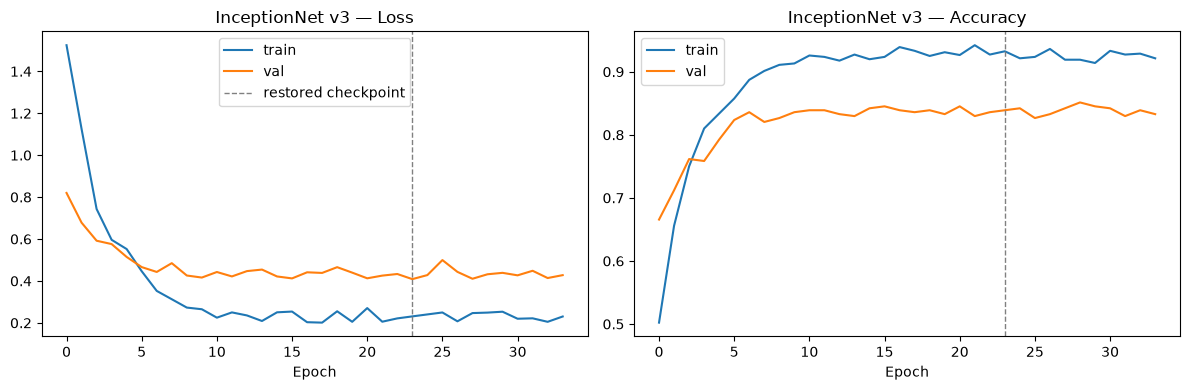

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "InceptionNet v3", is_inception=True,
    accum_steps=accum_steps,
)
plot_training_curves(history, "InceptionNet v3")

## Evaluate on the test set

[InceptionNet v3] Test accuracy: 0.773


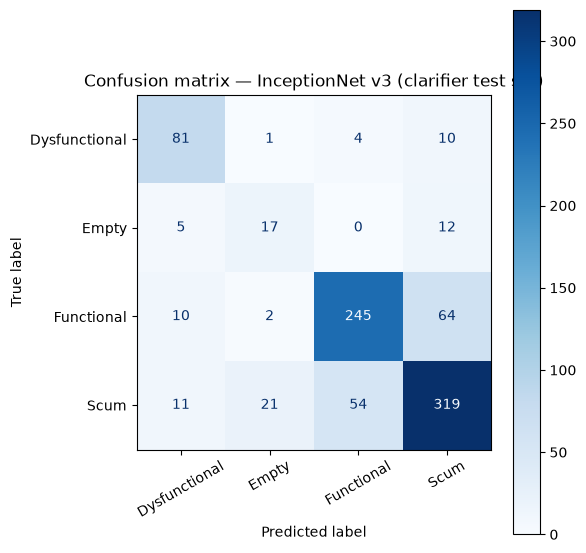

               precision    recall  f1-score   support

Dysfunctional      0.757     0.844     0.798        96
        Empty      0.415     0.500     0.453        34
   Functional      0.809     0.763     0.785       321
         Scum      0.788     0.788     0.788       405

     accuracy                          0.773       856
    macro avg      0.692     0.724     0.706       856
 weighted avg      0.777     0.773     0.775       856



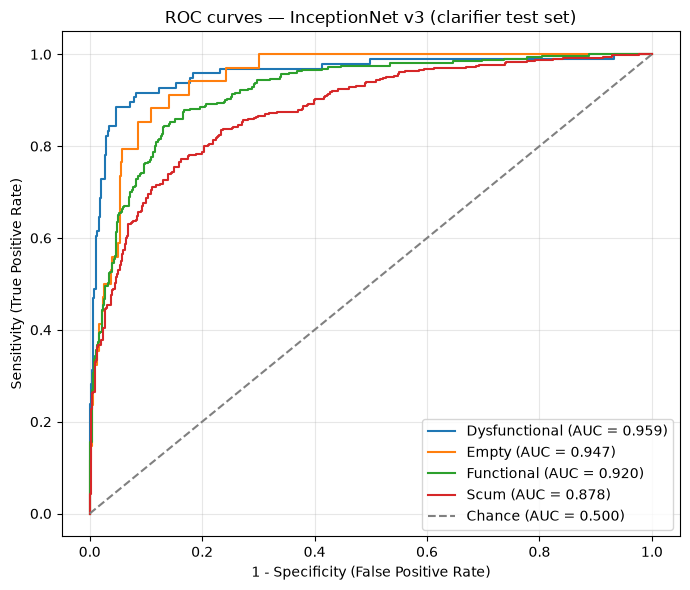

AUC (area under ROC curve) per class:
  Dysfunctional  : 0.959
  Empty          : 0.947
  Functional     : 0.920
  Scum           : 0.878

Mean AUC (over 4/4 classes with test examples): 0.926


(np.float64(0.7733644859813084),
 {'Dysfunctional': 0.959155701754386,
  'Empty': 0.9468656075568914,
  'Functional': 0.9195854077503129,
  'Scum': 0.8777093427499931})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "InceptionNet v3", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
)

## Save results + model weights to disk

In [6]:
save_result("InceptionNet v3", "inception_v3")

Saved results to ../results/clarifier_aug/results_clarifier_inception_v3_chronological.pkl
Saved model weights to ../models/pad/clarifier_inception_v3_cnn.pt
